# KNN known-attack classifier — training and validation
BENIGN is removed from both training and validation **before** sampling. Total allocation: 9,600 training, 1,200 validation and 1,200 test records from the existing separate Parquet partitions.


In [13]:
from pathlib import Path
import sys, json, importlib.util
import numpy as np
import pandas as pd
import joblib
ROOT=Path.cwd().resolve()
if ROOT.name.lower()=='knn_known' and ROOT.parent.name.lower()=='notebooks': ROOT=ROOT.parent.parent
elif ROOT.name.lower()=='notebooks': ROOT=ROOT.parent
MODULE_DIR=ROOT/'notebooks'/'knn_known'
if not (MODULE_DIR/'knn_known_flow.py').exists():
    MODULE_DIR=Path.cwd().resolve()
if not (MODULE_DIR / 'knn_known_flow.py').is_file():
    raise FileNotFoundError(f'Missing module: {MODULE_DIR / "knn_known_flow.py"}')
if str(MODULE_DIR) not in sys.path:
    sys.path.insert(0, str(MODULE_DIR))
# Load this exact file, avoiding stale Jupyter module cache.
spec = importlib.util.spec_from_file_location('knn_known_flow', MODULE_DIR / 'knn_known_flow.py')
knn_module = importlib.util.module_from_spec(spec)
sys.modules['knn_known_flow'] = knn_module
spec.loader.exec_module(knn_module)
read_data = knn_module.read_data
choose_columns = knn_module.choose_columns
feature_frame = knn_module.feature_frame
build_pipeline = knn_module.build_pipeline
save_artifact = knn_module.save_artifact
load_artifact = knn_module.load_artifact
predict_rows = knn_module.predict_rows
stratified_sample = knn_module.stratified_sample
print('Loaded KNN helper:', knn_module.__file__)
DATA=ROOT/'data'/'processed'/'Data_V3_SSH_Unknown_final'
MODEL=ROOT/'saved-models'/'knn_known'/'known_classifier.joblib'
OUT=ROOT/'outputs'/'results'/'knn_known'
FIG=ROOT/'outputs'/'figures'/'knn_known'
OUT.mkdir(parents=True,exist_ok=True);FIG.mkdir(parents=True,exist_ok=True)
print('Root:',ROOT)
print('Model:',MODEL)

Loaded KNN helper: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\notebooks\knn_known\knn_known_flow.py
Root: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection
Model: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\saved-models\knn_known\known_classifier.joblib


In [14]:
from sklearn.metrics import accuracy_score, f1_score

train = read_data(DATA / "known_train.parquet")
val = read_data(DATA / "known_validation.parquet")

# Remove BENIGN BEFORE sampling. KNN is a supervised ATTACK-ONLY classifier.
def attacks_only(frame, name):
    labels = frame["Label"].astype(str).str.strip()
    benign = labels.str.casefold().eq("benign")
    print(f"{name}: removed {int(benign.sum()):,} BENIGN rows")
    result = frame.loc[~benign].copy().reset_index(drop=True)
    result["Label"] = labels.loc[~benign].to_numpy()
    if result.empty:
        raise ValueError(f"{name}: no attack records remaining")
    return result

train = attacks_only(train, "Training")
val = attacks_only(val, "Validation")

# Total 12,000 across disjoint existing partitions:
# 9,600 training, 1,200 validation, 1,200 held-out testing.
# Retain all training records for classes with fewer than 100 examples.
train = stratified_sample(train, 9600, seed=42, preserve_rare=True)
val = stratified_sample(val, 1200, seed=43, preserve_rare=False)

columns = choose_columns(train)
X_train = feature_frame(train, columns)
y_train = train["Label"].astype(str).str.strip()
X_val = feature_frame(val, columns)
y_val = val["Label"].astype(str).str.strip()

assert len(train) == 9600 and len(val) == 1200
assert "label" not in {c.casefold() for c in columns}
assert not y_train.str.casefold().eq("benign").any()
assert not y_val.str.casefold().eq("benign").any()
if y_train.nunique() < 2:
    raise ValueError("Need at least two known attack classes for classification")
missing_train = sorted(set(y_val) - set(y_train))
if missing_train:
    raise ValueError(f"Validation classes absent from training: {missing_train}")
print("Training rows:", len(train), "Validation rows:", len(val))
print("Numeric features:", len(columns))
print("Training attack class counts:\n", y_train.value_counts().to_string())
print("Validation attack class counts:\n", y_val.value_counts().to_string())
print("BENIGN excluded; Label is used only as supervised target y.")


known_train.parquet: filtered 3990 attempted rows
known_validation.parquet: filtered 833 attempted rows
Training: removed 997,673 BENIGN rows
Validation: removed 213,809 BENIGN rows
Training rows: 9600 Validation rows: 1200
Numeric features: 82
Training attack class counts:
 Label
DoS Hulk                      3872
DDoS                          2324
Portscan                      2106
Infiltration - Portscan        899
DoS GoldenEye                  185
DoS Slowloris                   95
Web Attack - Brute Force        51
Infiltration                    22
Botnet                          18
Web Attack - XSS                13
Web Attack - SQL Injection       9
Heartbleed                       6
Validation attack class counts:
 Label
DoS Hulk                      487
DDoS                          292
Portscan                      264
Infiltration - Portscan       113
DoS GoldenEye                  24
DoS Slowloris                  12
Botnet                          3
Web Attack - SQL Inje

In [15]:
# Tune k on validation; NEVER use final test for hyperparameter selection.
from sklearn.metrics import accuracy_score, f1_score
from sklearn.base import clone
k_grid=[k for k in (3,5,7,9,11,15,21,31) if k<=len(X_train)]
records=[]
for k in k_grid:
    candidate=build_pipeline(k=k,weights='distance',metric='euclidean')
    candidate.fit(X_train,y_train)
    yp=candidate.predict(X_val)
    records.append({'k':k,'validation_accuracy':accuracy_score(y_val,yp),
                    'validation_macro_f1':f1_score(y_val,yp,average='macro',zero_division=0)})
    print('k=',k,'validation macro-F1=',round(records[-1]['validation_macro_f1'],5))
results=pd.DataFrame(records).sort_values(['validation_macro_f1','validation_accuracy','k'],ascending=[False,False,True])
display(results)
results.to_csv(OUT/'validation_k_search.csv',index=False)
best_k=int(results.iloc[0]['k'])
model=build_pipeline(k=best_k,weights='distance',metric='euclidean')
model.fit(X_train,y_train)
config={'best_k':best_k,'metric':'euclidean','weights':'distance','train_rows':len(train),
        'validation_rows':len(val),'test_rows':1200,'sample_seed':42,'sampling_policy':'12k total: 9600 train 1200 validation 1200 test; rare train classes under 100 retained','validation_macro_f1':float(results.iloc[0]['validation_macro_f1'])}
save_artifact(MODEL,model,columns,config)
(OUT/'training_summary.json').write_text(json.dumps({**config,'features':columns,'classes':list(model.classes_)},indent=2))
print('FITTED and SAVED:',MODEL)
print('Selected k:',best_k,'Classes:',list(model.classes_))

k= 3 validation macro-F1= 0.8953
k= 5 validation macro-F1= 0.81352
k= 7 validation macro-F1= 0.81395
k= 9 validation macro-F1= 0.80193
k= 11 validation macro-F1= 0.80193
k= 15 validation macro-F1= 0.81369
k= 21 validation macro-F1= 0.81512
k= 31 validation macro-F1= 0.69201


,k,validation_accuracy,validation_macro_f1
0,3,0.987500,0.895298
6,21,0.984167,0.815124
2,7,0.985000,0.813954
5,15,0.984167,0.813687
1,5,0.989167,0.813521
3,9,0.984167,0.801934
4,11,0.984167,0.801934
7,31,0.976667,0.692007


FITTED and SAVED: C:\Users\saaral\Desktop\gc\pattern recog\project\]code\Hybrid-Network-Intrusion-Detection\saved-models\knn_known\known_classifier.joblib
Selected k: 3 Classes: ['Botnet', 'DDoS', 'DoS GoldenEye', 'DoS Hulk', 'DoS Slowloris', 'Heartbleed', 'Infiltration', 'Infiltration - Portscan', 'Portscan', 'Web Attack - Brute Force', 'Web Attack - SQL Injection', 'Web Attack - XSS']


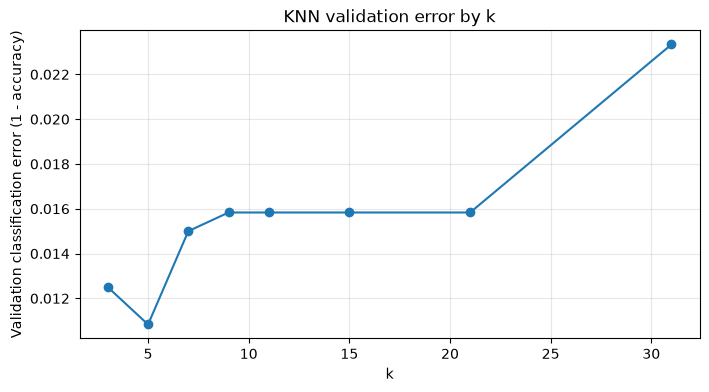

In [16]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,4))
plt.plot(results.sort_values('k')['k'],1-results.sort_values('k')['validation_accuracy'],marker='o')
plt.xlabel('k');plt.ylabel('Validation classification error (1 - accuracy)')
plt.title('KNN validation error by k');plt.grid(alpha=.3)
plt.savefig(FIG/'validation_error_by_k.png',dpi=150,bbox_inches='tight')
plt.show()